In [8]:
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
from matplotlib import rcParams, colors
from matplotlib import ticker as mticker
import geopandas as gpd
rcParams.update({'figure.autolayout': False})
import os
import wrf
from cartopy import crs as ccrs
import matplotlib.patches as patches
import cartopy.crs as ccrs
from cartopy.feature import ShapelyFeature
from cartopy.io.shapereader import Reader
from cartopy.mpl.gridliner import LATITUDE_FORMATTER, LONGITUDE_FORMATTER
from shapely.geometry import mapping
import glob
import pandas as pd
import cartopy.feature as cfeature
import pickle
import rioxarray
import xesmf as xe
import dask
from dask.distributed import Client, LocalCluster
from dask import delayed
import dask.array as da
from dask_jobqueue import PBSCluster
import xarray as xr
from concurrent.futures import ProcessPoolExecutor
import calendar
import zarr
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
# Setup your PBSCluster
cluster = PBSCluster(
    cores=10,  # Total number of cores across all processes
    memory='300GB',  # Memory per worker
    processes=10,  # Number of processes per worker (1 process per core)
    queue='casper',  # The type of queue to utilize
    local_directory='/glade/derecho/scratch/adixit/tmp/',  # Use your local directory
    resource_spec='select=1:ncpus=10:mem=300GB',  # Resources per worker
    account='WYOM0169',  # Project ID
    walltime='6:00:00',  # Wall time
    #interface='ib0',  # Interface to use (if needed)
)

cluster.scale(jobs=1)  # This will create 200 workers
client = Client(cluster)

In [4]:
client

<Client: 'tcp://128.117.208.179:43227' processes=10 threads=10, memory=279.40 GiB>

## Create V200 file for hovmoller plot

In [6]:
import os
import glob
import xarray as xr
import dask

indir = "/glade/campaign/collections/rda/data/d633000/e5.oper.an.pl/"
outdir = "/glade/derecho/scratch/adixit/India_Heatwave/DATA/era5_data/V200/"
varname = "V"

@dask.delayed
def process_year(year):
    file_pattern = os.path.join(indir, f"{year}*", f"*_{varname.lower()}.*.nc")

    files = sorted(glob.glob(file_pattern))

    ds = xr.open_mfdataset(
        files,
        combine="by_coords",
        parallel=True,
        engine="netcdf4")

    da = ds[varname].sel(level=200)
    da = da.sortby("time")
    da_daily = da.resample(time="1D").mean()
    outpath = os.path.join(outdir, f"e5.oper.an.pl.{varname}.200hPa.daily.{year}.nc")
    return da_daily#.to_netcdf(outpath)

#tasks = [process_year(year) for year in range(1944, 2025)]    

In [29]:
@dask.delayed
def process_file(file):
    data = xr.open_mfdataset(
        file,
        combine="by_coords",
        parallel=True,
        engine="netcdf4")
    data = data.sel(level=200)
    #data = data.resample(time="1D").mean()
    return data

In [11]:
def p_year(year):
    outpath = os.path.join(outdir, f"e5.oper.an.pl.{varname}.200hPa.daily.{year}.nc")
    data = process_year(year)
    data = dask.compute(data)[0]
    data.to_netcdf(outpath, compute=False)

In [13]:
shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
india = gpd.read_file(shp_file).dissolve()
shape_feature = ShapelyFeature(india.geometry, ccrs.PlateCarree(),edgecolor='black', facecolor='none', lw=0.75)

In [11]:
files = glob.glob('/glade/derecho/scratch/adixit/India_Heatwave/DATA/era5_data/V200/*.nc')
files = sorted(files)

months = [ 5,6]
ds_v = []
for file in files:
    ds = xr.open_mfdataset(file)
    ds = ds.sel(time=ds.time.dt.month.isin(months))
    ds = ds.sel(latitude = slice(80,30))
    ds = ds.mean(dim='latitude')
    ds_v.append(ds)

dsv = xr.concat(ds_v,dim='time')

In [12]:
dsv = dask.compute(dsv)[0]

In [29]:
from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    '#7e170e', '#941d12', '#a92419', '#b73022', '#c6412d',
    '#d0582e', '#db7232', '#e8ab78', '#f7e5d5', '#ffffff',
    '#ffffff', '#e4eff5', '#a5c6dd', '#71a2c9', '#5384b7',
    '#3666a7', '#2f4f9c', '#293891', '#1f2c7b', '#132161'
])

In [14]:
start_year = '1950'
end_year = '2024'

dsv = dsv.sel(time=slice(start_year+'-01-01',end_year+'-12-31'))

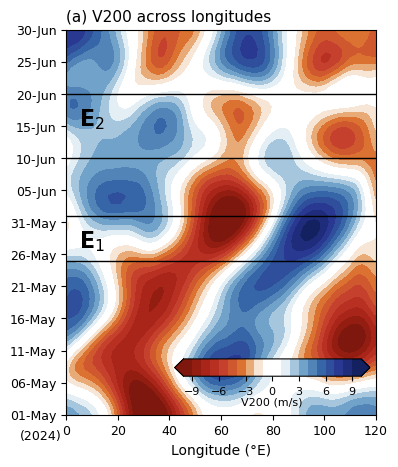

In [28]:
from scipy.ndimage import gaussian_filter

data = dsv.V.sel(time=slice('2024-05-01', '2024-06-30'),
                 longitude=slice(0, 120))
data = data.copy(data=gaussian_filter(data.values, sigma=(3,3)))

f, ax = plt.subplots(figsize=(4, 5))
pc = ax.contourf(data.longitude, data.time, data,
                 levels=np.arange(-10, 10.1, 1), cmap=cmap, extend='both')

for date in ['2024-05-25', '2024-06-01', '2024-06-10', '2024-06-20']:
    ax.axhline(pd.Timestamp(date), color='k', linewidth=1)

ax.text(5, pd.Timestamp('2024-05-27'), r'$\mathbf{E}_1$', fontsize=16)
ax.text(5, pd.Timestamp('2024-06-15'), r'$\mathbf{E}_2$', fontsize=16)

dates = pd.date_range('2024-05-01', '2024-06-30', freq='5D')
ax.set_yticks(dates)
ax.set_yticklabels(dates.strftime('%d-%b'))

ax.set_xlim(0, 120)
ax.set_xticks(np.arange(0, 121, 20))
ax.set_xlabel('Longitude (°E)')
ax.set_title('(a) V200 across longitudes', loc='left', fontsize=11)
ax.text(-0.15, -0.065, '(2024)', transform=ax.transAxes, fontsize=9)
ax.tick_params(labelsize=9)

cax = ax.inset_axes([0.35, 0.10, 0.63, 0.045])
cb = f.colorbar(pc, cax=cax, orientation='horizontal',
                ticks=np.arange(-9, 10, 3))
cb.ax.tick_params(labelsize=8)
cb.set_label('V200 (m/s)', fontsize=8, labelpad=1)

plt.show()

## Plotting Z500 anomaly

In [62]:
shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
india = gpd.read_file(shp_file).dissolve()
shape_feature = ShapelyFeature(india.geometry, ccrs.PlateCarree(),edgecolor='black', facecolor='none', lw=0.75)

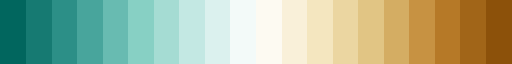

In [63]:
from matplotlib.colors import LinearSegmentedColormap
combined_colors = ['#8c510a','#bf812d','#dfc27d','#f6e8c3','#ffffff','#c7eae5','#80cdc1','#35978f','#01665e'][::-1]
def create_gradient_colormap(n_colors, color_list=combined_colors):
    return LinearSegmentedColormap.from_list("custom_gradient", color_list, N=n_colors)
cmap1 = create_gradient_colormap(20,combined_colors)
cmap1

In [70]:
p = "/glade/derecho/scratch/adixit/India_Heatwave/DATA/z_anom.1950-2024.nc"

T = slice("2024-05-25", "2024-06-01")
lat = slice(80, 20)
lon = slice(0, 120)
lev = 500
z = xr.open_dataset(p, chunks="auto").Z500.sel(time=T, latitude=lat, longitude=lon).mean("time") / 9.80665

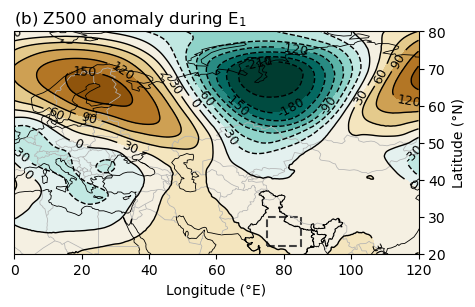

In [71]:
f = plt.figure(figsize=(5, 3))
ax = f.add_subplot(111, projection=ccrs.PlateCarree())

ax.contourf(z.longitude, z.latitude, z,levels=np.arange(-210, 211, 30), cmap='BrBG_r',extend='both', transform=ccrs.PlateCarree())

cs = ax.contour(z.longitude, z.latitude, z,levels=np.arange(-210, 211, 30),colors='k', linewidths=1,transform=ccrs.PlateCarree())
ax.clabel(cs, fmt='%d', fontsize=9)

ax.coastlines(linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.55, edgecolor='0.7')
ax.add_feature(shape_feature)

rectangle = patches.Rectangle((75, 22), 10, 8, fill=False, edgecolor='0.25',linewidth=1.5, linestyle='--', transform=ccrs.PlateCarree())
ax.add_patch(rectangle)

ax.set_extent([0, 120, 20, 80], crs=ccrs.PlateCarree())
ax.set_xticks(np.arange(0, 121, 20), crs=ccrs.PlateCarree())
ax.set_yticks(np.arange(20, 81, 10), crs=ccrs.PlateCarree())
ax.yaxis.tick_right()
ax.yaxis.set_label_position('right')
ax.set_aspect(1.1)
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')
ax.set_title(r'(b) Z500 anomaly during E$_1$', loc='left')

plt.tight_layout()
plt.savefig('z500_e1.pdf',format='pdf',dpi=300,transparent=True)
plt.show()

In [66]:
p = "/glade/derecho/scratch/adixit/India_Heatwave/DATA/z_anom.1950-2024.nc"

T = slice("2024-06-10", "2024-06-20")
lat = slice(80, 20)
lon = slice(0, 120)
lev = 500
z = xr.open_dataset(p, chunks="auto").Z500.sel(time=T, latitude=lat, longitude=lon).mean("time") / 9.80665

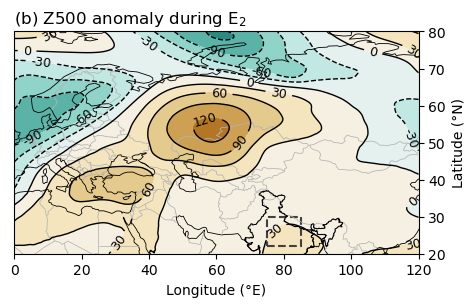

In [67]:
f = plt.figure(figsize=(5, 3))
ax = f.add_subplot(111, projection=ccrs.PlateCarree())

ax.contourf(z.longitude, z.latitude, z,levels=np.arange(-210, 211, 30), cmap='BrBG_r',extend='both', transform=ccrs.PlateCarree())

cs = ax.contour(z.longitude, z.latitude, z,levels=np.arange(-210, 211, 30),colors='k', linewidths=1,transform=ccrs.PlateCarree())
ax.clabel(cs, fmt='%d', fontsize=9)

ax.coastlines(linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.55, edgecolor='0.7')
ax.add_feature(shape_feature)

rectangle = patches.Rectangle((75, 22), 10, 8, fill=False, edgecolor='0.25',linewidth=1.5, linestyle='--', transform=ccrs.PlateCarree())
ax.add_patch(rectangle)

ax.set_extent([0, 120, 20, 80], crs=ccrs.PlateCarree())
ax.set_xticks(np.arange(0, 121, 20), crs=ccrs.PlateCarree())
ax.set_yticks(np.arange(20, 81, 10), crs=ccrs.PlateCarree())
ax.yaxis.tick_right()
ax.yaxis.set_label_position('right')
ax.set_aspect(1.1)
ax.set_xlabel('Longitude (°E)')
ax.set_ylabel('Latitude (°N)')
ax.set_title(r'(b) Z500 anomaly during E$_2$', loc='left')

plt.tight_layout()
plt.savefig('z500_e2.pdf',format='pdf',dpi=300,transparent=True)
plt.show()